<a href="https://colab.research.google.com/github/DanilZhigaylo/nlp-audio-classification-case5/blob/main/case5_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import zipfile

with zipfile.ZipFile("dataset.txt.zip", "r") as zf:
    zf.extractall(".")

print("dataset.txt существует:", os.path.exists("dataset.txt"))
print("Размер dataset.txt (байт):", os.path.getsize("dataset.txt"))

with open("dataset.txt", "r", encoding="utf-8", errors="replace") as f:
    for i in range(10):
        line = f.readline()
        if not line:
            break
        print(f"{i}: {repr(line[:250])}")

dataset.txt существует: True
Размер dataset.txt (байт): 39268580
0: '__label__INSULT скотина! что сказать\n'
1: '__label__NORMAL я сегодня проезжала по рабочей и между домами снитенко и гомолысовой магазином ( на пустыре) бежала кошка похожего окраса. может, я и ошиблась, но необычный окрас бросился в глаза.\n'
2: '__label__NORMAL очередной лохотрон. зачем придумывать очередной налог на воздух, если можно обьявить инсульт и грипп- пандемией! и лихо на придурках зарабатывать годами на штрафах, фейковых вакцинах, всевозможных платных тестах, продажей масок и перч'
3: '__label__NORMAL ретро дежавю ... сложно понять чужое сердце , лиш ощутить музыкой видимо\n'
4: '__label__NORMAL а когда мы статус агрогородка получили?\n'
5: '__label__NORMAL 2 августа поздно вечером нашли вот такую потеряшку в районе высоток на победе. девочка явно домашняя, в новом ошейнике. обращаться +7 989 816-43-42\n'
6: '__label__NORMAL вчера надыбала новые стикеры #u2a94ec7fabs#\n'
7: '__label__INSULT,__label__THR

In [2]:
import pandas as pd

records = []
with open("dataset.txt", "r", encoding="utf-8", errors="replace") as f:
    for line in f:
        line = line.strip()
        if not line or " " not in line:
            continue
        labels_part, text_part = line.split(" ", 1)
        # Берем первую метку и убираем префикс '__label__'
        main_label = labels_part.split(",")[0].replace("__label__", "").strip()
        text_part = text_part.strip()
        if main_label and text_part:
            records.append({"text": text_part, "target": main_label})

data = pd.DataFrame(records)
print("Всего строк разобрано:", len(data))
print("\nРаспределение классов:\n", data["target"].value_counts())
print("\nПримеры:\n", data.head(5))

Всего строк разобрано: 248290

Распределение классов:
 target
NORMAL       203685
INSULT        36826
THREAT         5460
OBSCENITY      2319
Name: count, dtype: int64

Примеры:
                                                 text  target
0                               скотина! что сказать  INSULT
1  я сегодня проезжала по рабочей и между домами ...  NORMAL
2  очередной лохотрон. зачем придумывать очередно...  NORMAL
3  ретро дежавю ... сложно понять чужое сердце , ...  NORMAL
4            а когда мы статус агрогородка получили?  NORMAL


In [3]:
import re

def preprocess_text(text: str) -> str:
    text = text.lower().replace("ё", "е")
    text = re.sub(r"http\S+|www\S+|#\S+", " ", text)
    text = re.sub(r"[^а-яa-z0-9\s]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["clean_text"] = data["text"].apply(preprocess_text)
data = data[data["clean_text"].str.len() > 0].reset_index(drop=True)

print("Строк после очистки:", len(data))
data[["text", "clean_text", "target"]].head(5)

Строк после очистки: 248257


,text,clean_text,target
0,скотина! что сказать,скотина что сказать,INSULT
1,я сегодня проезжала по рабочей и между домами ...,я сегодня проезжала по рабочей и между домами ...,NORMAL
2,очередной лохотрон. зачем придумывать очередно...,очередной лохотрон зачем придумывать очередной...,NORMAL
3,"ретро дежавю ... сложно понять чужое сердце , ...",ретро дежавю сложно понять чужое сердце лиш ощ...,NORMAL
4,а когда мы статус агрогородка получили?,а когда мы статус агрогородка получили,NORMAL


In [4]:
from sklearn.model_selection import train_test_split

SEED = 42

train_val_df, test_df = train_test_split(
    data,
    test_size=0.15,
    random_state=SEED,
    stratify=data["target"]
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_df["target"]
)

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 173779, Val: 37239, Test: 37239


In [5]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import accuracy_score, f1_score

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_features=100000
)

X_train = vectorizer.fit_transform(train_df["clean_text"])
X_val = vectorizer.transform(val_df["clean_text"])
X_test = vectorizer.transform(test_df["clean_text"])

y_train = train_df["target"].values
y_val = val_df["target"].values
y_test = test_df["target"].values

model_lr = LogisticRegression(max_iter=1000, C=2.0, random_state=SEED)
model_nb = ComplementNB(alpha=0.5)

model_lr.fit(X_train, y_train)
model_nb.fit(X_train, y_train)

for name, model in [("LogReg", model_lr), ("ComplementNB", model_nb)]:
    val_pred = model.predict(X_val)
    print(f"{name} (VAL) -> Accuracy: {accuracy_score(y_val, val_pred):.4f}, Macro F1: {f1_score(y_val, val_pred, average='macro'):.4f}")

LogReg (VAL) -> Accuracy: 0.9436, Macro F1: 0.7575
ComplementNB (VAL) -> Accuracy: 0.8757, Macro F1: 0.6519


In [6]:
from sklearn.metrics import classification_report

proba_val_lr = model_lr.predict_proba(X_val)
proba_val_nb = model_nb.predict_proba(X_val)
classes = model_lr.classes_

best_w = 0.5
best_val_acc = -1.0

for w in np.linspace(0, 1, 101):
    blend_proba = w * proba_val_lr + (1 - w) * proba_val_nb
    pred_val = classes[np.argmax(blend_proba, axis=1)]
    acc = accuracy_score(y_val, pred_val)
    if acc > best_val_acc:
        best_val_acc = acc
        best_w = w

print(f"Лучший вес LogReg на VAL: {best_w:.2f} (ComplementNB: {1 - best_w:.2f}), Val Accuracy: {best_val_acc:.4f}")

proba_test_lr = model_lr.predict_proba(X_test)
proba_test_nb = model_nb.predict_proba(X_test)
test_pred_ensemble = classes[np.argmax(best_w * proba_test_lr + (1 - best_w) * proba_test_nb, axis=1)]

print("\n=== ИТОГ НА TEST (Ансамбль) ===")
print("Test Accuracy:", f"{accuracy_score(y_test, test_pred_ensemble):.4f}")
print("Test Macro F1:", f"{f1_score(y_test, test_pred_ensemble, average='macro'):.4f}")
print("\nОтчёт по классам:\n", classification_report(y_test, test_pred_ensemble, digits=4))

Лучший вес LogReg на VAL: 0.47 (ComplementNB: 0.53), Val Accuracy: 0.9477

=== ИТОГ НА TEST (Ансамбль) ===
Test Accuracy: 0.9503
Test Macro F1: 0.7680

Отчёт по классам:
               precision    recall  f1-score   support

      INSULT     0.8811    0.8211    0.8501      5524
      NORMAL     0.9644    0.9886    0.9763     30548
   OBSCENITY     0.8110    0.3822    0.5195       348
      THREAT     0.8494    0.6337    0.7259       819

    accuracy                         0.9503     37239
   macro avg     0.8765    0.7064    0.7680     37239
weighted avg     0.9481    0.9503    0.9478     37239



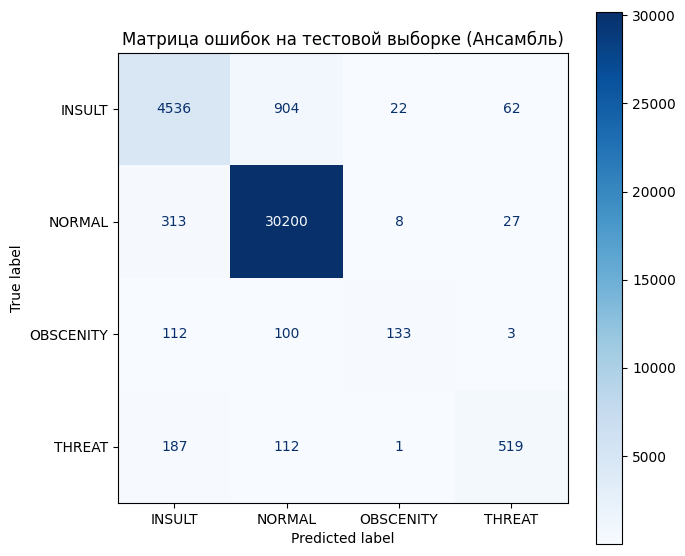

Всего ошибок на тесте: 1851 из 37239 (4.97%)

Топ пар ошибок (истинный -> предсказанный):
true_label  pred_label
INSULT      NORMAL        904
NORMAL      INSULT        313
THREAT      INSULT        187
OBSCENITY   INSULT        112
THREAT      NORMAL        112
OBSCENITY   NORMAL        100
INSULT      THREAT         62
NORMAL      THREAT         27
INSULT      OBSCENITY      22
NORMAL      OBSCENITY       8
OBSCENITY   THREAT          3
THREAT      OBSCENITY       1
dtype: int64

Примеры ошибок (до 10 штук):
[THREAT -> NORMAL | p=0.45] она живая интересно или нет.... я бы пристрелил за такое...
[THREAT -> NORMAL | p=0.52] кусать то не будут... но когда они гундят, убить любого готов
[THREAT -> NORMAL | p=0.63] её надо в темны́й погреб и пусть там пробудет минимум с неделю на воде
[OBSCENITY -> INSULT | p=0.52] дай уже мне ебать эту жопу
[NORMAL -> INSULT | p=0.41] в дряхлый очко хоть мешок клади
[INSULT -> NORMAL | p=0.68] николай вы молодец!!! едросы трусы!
[INSULT -> NORMAL | p=0.5

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Получаем предсказания вероятностей на TEST
proba_test_blend = best_w * proba_test_lr + (1 - best_w) * proba_test_nb

# 1. Матрица ошибок
cm = confusion_matrix(y_test, test_pred_ensemble, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Матрица ошибок на тестовой выборке (Ансамбль)")
plt.tight_layout()
plt.show()

# 2. Таблица ошибок для ручного анализа
test_analysis = test_df.copy().reset_index(drop=True)
test_analysis["true_label"] = y_test
test_analysis["pred_label"] = test_pred_ensemble
test_analysis["max_proba"] = proba_test_blend.max(axis=1)

errors_df = test_analysis[test_analysis["true_label"] != test_analysis["pred_label"]].copy()
print(f"Всего ошибок на тесте: {len(errors_df)} из {len(test_analysis)} ({len(errors_df)/len(test_analysis)*100:.2f}%)")
print("\nТоп пар ошибок (истинный -> предсказанный):")
print(errors_df.groupby(["true_label", "pred_label"]).size().sort_values(ascending=False))

print("\nПримеры ошибок (до 10 штук):")
for idx, row in errors_df.head(10).iterrows():
    print(f"[{row['true_label']} -> {row['pred_label']} | p={row['max_proba']:.2f}] {row['text'][:160]}")

# 3. Простая пост-обработка: подбираем множитель для класса OBSCENITY на VAL
proba_val_blend = best_w * proba_val_lr + (1 - best_w) * proba_val_nb
val_true = val_df["target"].values

best_mult = 1.0
best_val_f1 = f1_score(val_true, classes[np.argmax(proba_val_blend, axis=1)], average="macro")

if "OBSCENITY" in classes:
    obs_idx = list(classes).index("OBSCENITY")
    for mult in np.linspace(1.0, 4.0, 31):
        adj_proba = proba_val_blend.copy()
        adj_proba[:, obs_idx] *= mult
        pred_v = classes[np.argmax(adj_proba, axis=1)]
        macro_f1 = f1_score(val_true, pred_v, average="macro")
        if macro_f1 > best_val_f1:
            best_val_f1 = macro_f1
            best_mult = mult

    adj_test_proba = proba_test_blend.copy()
    adj_test_proba[:, obs_idx] *= best_mult
    test_pred_post = classes[np.argmax(adj_test_proba, axis=1)]
    print(f"\nПост-обработка (множитель OBSCENITY = {best_mult:.2f}, подобран на VAL):")
    print(f"Test Accuracy после пост-обработки: {accuracy_score(y_test, test_pred_post):.4f}")
    print(f"Test Macro F1 после пост-обработки: {f1_score(y_test, test_pred_post, average='macro'):.4f}")
    print(classification_report(y_test, test_pred_post, digits=4))